# CU-BEMS Smart Building — Exploratory Data Analysis (Starter)

**Dataset:** CU-BEMS Smart Building Energy & Indoor Environmental Data (Kaggle)
7 floors · Jul 2018–Dec 2019 · 1-minute sampling · AC power, lighting, plug loads, temperature, humidity, ambient light

This notebook is a starting point for exploration:
1. Load & combine the CSV files
2. Inspect structure, dtypes, date range
3. Check missing / noisy data
4. Visualize trends (AC power, lighting, temp) over time
5. Basic summary stats & correlations

> Note: CU-BEMS ships as ~14 CSV files (one per floor per year). Column names can vary slightly between files — this notebook auto-detects common patterns, but **always print `df.columns` after loading and adjust names if needed.**


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (12, 4)


## 2. Load the data

This notebook lives in `workspace/`, with the CSVs in a sibling `data/` folder at the repo root:

```
is4001-g1-smart-building/
├── data/
└── workspace/
    └── cubems_eda_starter.ipynb   <- you are here
```


In [2]:
DATA_DIR = '../data'   # relative to workspace/ — adjust if your layout differs

csv_files = sorted(glob.glob(os.path.join(DATA_DIR, '*.csv')))
print(f"Found {len(csv_files)} CSV files:")
for f in csv_files:
    print(' -', os.path.basename(f))


Found 14 CSV files:
 - 2018Floor1.csv
 - 2018Floor2.csv
 - 2018Floor3.csv
 - 2018Floor4.csv
 - 2018Floor5.csv
 - 2018Floor6.csv
 - 2018Floor7.csv
 - 2019Floor1.csv
 - 2019Floor2.csv
 - 2019Floor3.csv
 - 2019Floor4.csv
 - 2019Floor5.csv
 - 2019Floor6.csv
 - 2019Floor7.csv


In [3]:
# Peek at one file first to understand structure before bulk-loading
sample = pd.read_csv(csv_files[0], nrows=5)
sample


,Date,z1_Light(kW),z1_Plug(kW),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_Light(kW),z2_Plug(kW),z3_Light(kW),z3_Plug(kW),z4_Light(kW)
0,2018-07-01 00:00:00,12.94,18.56,45.24,0.01,0.01,0.00,13.76,17.64,10.92,0.89,35.76
1,2018-07-01 00:01:00,12.97,18.55,45.28,0.02,0.01,0.01,13.76,17.21,10.95,0.87,35.81
2,2018-07-01 00:02:00,12.97,18.55,45.24,0.01,0.01,0.01,13.79,17.18,10.94,0.86,35.78
3,2018-07-01 00:03:00,12.98,18.58,45.26,0.02,0.01,0.00,13.81,16.64,10.94,0.85,35.83
4,2018-07-01 00:04:00,13.01,18.60,45.22,0.02,0.01,0.01,13.83,15.69,10.97,0.85,35.86


## 3. Combine files into one DataFrame

Since each file is a floor/year, we tag each row with its source file so you can filter by floor/year later.
Adjust `parse_dates` / date column name once you've seen the real columns above.


In [5]:
def load_one(path):
    df = pd.read_csv(path)
    df['source_file'] = os.path.basename(path)
    return df

df_list = [load_one(f) for f in csv_files]
df = pd.concat(df_list, ignore_index=True)
print(df.shape)
df.head()


(5432489, 50)


,Date,z1_Light(kW),z1_Plug(kW),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_Light(kW),z2_Plug(kW),z3_Light(kW),z3_Plug(kW),z4_Light(kW),source_file,z1_AC1(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW),z2_AC11(kW),z2_AC12(kW),z2_AC13(kW),z2_AC14(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_S1(degC),z3_S1(RH%),z3_S1(lux),z4_AC1(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),z4_AC2(kW),z4_AC3(kW),z4_AC4(kW)
0,2018-07-01 00:00:00,12.94,18.56,45.24,0.01,0.01,0.00,13.76,17.64,10.92,0.89,35.76,2018Floor1.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-07-01 00:01:00,12.97,18.55,45.28,0.02,0.01,0.01,13.76,17.21,10.95,0.87,35.81,2018Floor1.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2018-07-01 00:02:00,12.97,18.55,45.24,0.01,0.01,0.01,13.79,17.18,10.94,0.86,35.78,2018Floor1.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2018-07-01 00:03:00,12.98,18.58,45.26,0.02,0.01,0.00,13.81,16.64,10.94,0.85,35.83,2018Floor1.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2018-07-01 00:04:00,13.01,18.60,45.22,0.02,0.01,0.01,13.83,15.69,10.97,0.85,35.86,2018Floor1.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Identify likely datetime column (common CU-BEMS names: 'Date', 'Date/Time', 'timestamp')
candidate_date_cols = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
print("Candidate date columns:", candidate_date_cols)

# Once confirmed, set the right name here:
DATE_COL = candidate_date_cols[0] if candidate_date_cols else None
if DATE_COL:
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors='coerce')
    print(df[DATE_COL].min(), '→', df[DATE_COL].max())


Candidate date columns: ['Date']
2018-07-01 00:00:00 → 2019-12-31 23:59:00


## 4. Structure overview

In [7]:
print("Shape:", df.shape)
print("\nColumn dtypes:")
print(df.dtypes)


Shape: (5432489, 50)

Column dtypes:
Date            datetime64[ns]
z1_Light(kW)           float64
z1_Plug(kW)            float64
z2_AC1(kW)             float64
z2_AC2(kW)             float64
z2_AC3(kW)             float64
z2_AC4(kW)             float64
z2_Light(kW)           float64
z2_Plug(kW)            float64
z3_Light(kW)           float64
z3_Plug(kW)            float64
z4_Light(kW)           float64
source_file             object
z1_AC1(kW)             float64
z1_S1(degC)            float64
z1_S1(RH%)             float64
z1_S1(lux)             float64
z2_AC5(kW)             float64
z2_AC6(kW)             float64
z2_AC7(kW)             float64
z2_AC8(kW)             float64
z2_AC9(kW)             float64
z2_AC10(kW)            float64
z2_AC11(kW)            float64
z2_AC12(kW)            float64
z2_AC13(kW)            float64
z2_AC14(kW)            float64
z2_S1(degC)            float64
z2_S1(RH%)             float64
z2_S1(lux)             float64
z3_S1(degC)            float64
z3

In [8]:
df.describe(include='all').T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,5432488,NaN,NaN,NaN,2019-03-28 00:46:01.059186432,2018-07-01 00:00:00,2018-11-12 17:37:00,2019-03-27 11:14:00,2019-08-09 04:52:00,2019-12-31 23:59:00,NaN
z1_Light(kW),5274002.0,NaN,NaN,NaN,2.36176,0.0,0.0,0.01,3.6,162.24,4.298605
z1_Plug(kW),5326868.0,NaN,NaN,NaN,0.867814,0.0,0.13,0.3,0.75,97.08,2.074178
z2_AC1(kW),5187511.0,NaN,NaN,NaN,8.037935,0.0,0.0,0.0,13.14,131.55,14.547687
z2_AC2(kW),1576316.0,NaN,NaN,NaN,2.863716,0.0,0.02,0.03,1.16,798.72,9.334283
z2_AC3(kW),1576315.0,NaN,NaN,NaN,0.214848,0.0,0.0,0.01,0.02,24.95,0.373724
z2_AC4(kW),1576315.0,NaN,NaN,NaN,0.239387,0.0,0.0,0.01,0.03,2.04,0.417855
z2_Light(kW),5251933.0,NaN,NaN,NaN,2.751307,0.0,0.0,0.81,4.09,236.16,4.08488
z2_Plug(kW),5224161.0,NaN,NaN,NaN,2.379682,0.0,0.03,0.12,0.52,73.68,5.454011
z3_Light(kW),5324347.0,NaN,NaN,NaN,3.61058,0.0,0.05,0.35,1.05,4762.43,9.223448


## 5. Missing / data quality check

CU-BEMS is explicitly *not* perfectly cleaned — expect gaps, so check this early and document what you find.


In [9]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary[missing_summary['missing_count'] > 0]


,missing_count,missing_pct
z3_S1(lux),4906752,90.32
z3_S1(degC),4906749,90.32
z3_S1(RH%),4906748,90.32
z4_AC2(kW),4746287,87.37
z4_AC3(kW),4746287,87.37
z4_AC4(kW),4744441,87.33
z2_AC6(kW),4643072,85.47
z2_AC9(kW),4643072,85.47
z2_AC12(kW),4643072,85.47
z2_AC13(kW),4643072,85.47


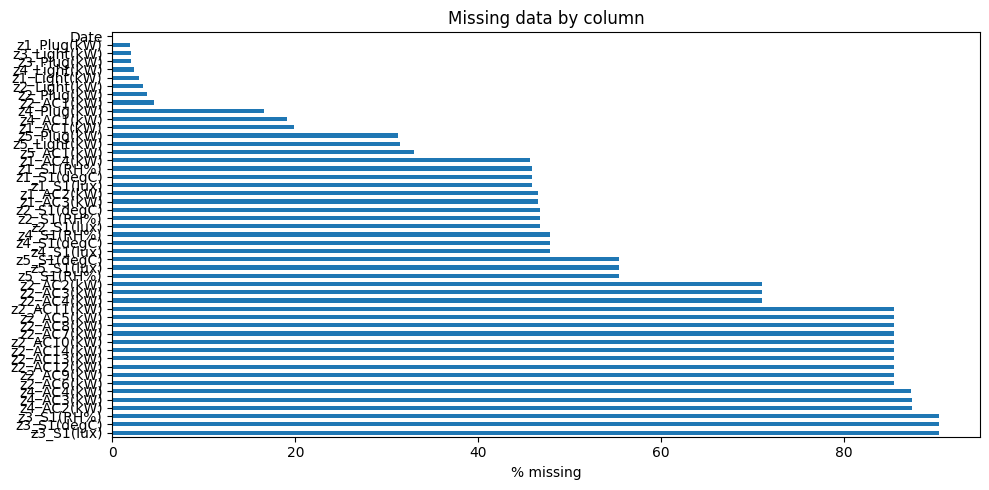

In [10]:
# Visualize missingness by column
fig, ax = plt.subplots(figsize=(10, 5))
missing_summary[missing_summary['missing_count'] > 0]['missing_pct'].plot(kind='barh', ax=ax)
ax.set_xlabel('% missing')
ax.set_title('Missing data by column')
plt.tight_layout()
plt.show()


In [11]:
# If you have a date column, check for gaps in the time series (expected 1-min interval)
if DATE_COL:
    ts = df[[DATE_COL]].dropna().sort_values(DATE_COL)
    gaps = ts[DATE_COL].diff()
    print("Gap distribution (top 10 largest gaps):")
    print(gaps.sort_values(ascending=False).head(10))


Gap distribution (top 10 largest gaps):
1893476   0 days 00:01:00
4193578   0 days 00:01:00
3771242   0 days 00:01:00
2388410   0 days 00:01:00
2775315   0 days 00:01:00
464912    0 days 00:01:00
4578288   0 days 00:01:00
80298     0 days 00:01:00
2825622   0 days 00:01:00
2582406   0 days 00:01:00
Name: Date, dtype: timedelta64[ns]


## 6. Trends over time

Pick actual column names from `df.columns` above (e.g. an AC power zone, a lighting zone, temperature).
Replace the placeholders below.


In [12]:
# Inspect available numeric columns to choose from
numeric_cols = df.select_dtypes(include='number').columns.tolist()
print(numeric_cols)


['z1_Light(kW)', 'z1_Plug(kW)', 'z2_AC1(kW)', 'z2_AC2(kW)', 'z2_AC3(kW)', 'z2_AC4(kW)', 'z2_Light(kW)', 'z2_Plug(kW)', 'z3_Light(kW)', 'z3_Plug(kW)', 'z4_Light(kW)', 'z1_AC1(kW)', 'z1_S1(degC)', 'z1_S1(RH%)', 'z1_S1(lux)', 'z2_AC5(kW)', 'z2_AC6(kW)', 'z2_AC7(kW)', 'z2_AC8(kW)', 'z2_AC9(kW)', 'z2_AC10(kW)', 'z2_AC11(kW)', 'z2_AC12(kW)', 'z2_AC13(kW)', 'z2_AC14(kW)', 'z2_S1(degC)', 'z2_S1(RH%)', 'z2_S1(lux)', 'z3_S1(degC)', 'z3_S1(RH%)', 'z3_S1(lux)', 'z4_AC1(kW)', 'z4_Plug(kW)', 'z4_S1(degC)', 'z4_S1(RH%)', 'z4_S1(lux)', 'z1_AC2(kW)', 'z1_AC3(kW)', 'z1_AC4(kW)', 'z5_AC1(kW)', 'z5_Light(kW)', 'z5_Plug(kW)', 'z5_S1(degC)', 'z5_S1(RH%)', 'z5_S1(lux)', 'z4_AC2(kW)', 'z4_AC3(kW)', 'z4_AC4(kW)']


C:\Users\Willi\AppData\Local\Temp\ipykernel_1704\2928944027.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  plot_df = plot_df.set_index(DATE_COL).resample('1H').mean()


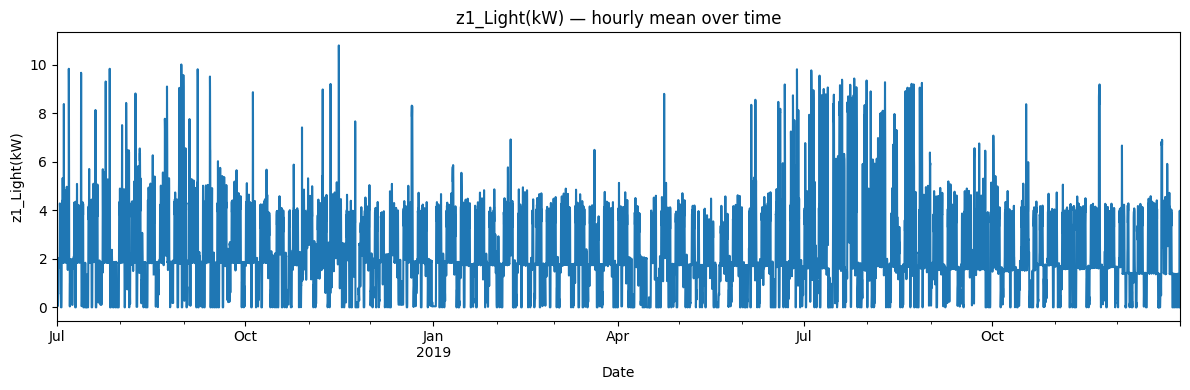

In [13]:
# --- Example: plot one numeric column over time ---
COL_TO_PLOT = numeric_cols[0]  # <-- replace with e.g. an AC power / lighting column name

if DATE_COL:
    plot_df = df[[DATE_COL, COL_TO_PLOT]].dropna().sort_values(DATE_COL)
    # Resample to hourly mean for a readable plot (1-min data is very dense)
    plot_df = plot_df.set_index(DATE_COL).resample('1H').mean()

    fig, ax = plt.subplots()
    plot_df[COL_TO_PLOT].plot(ax=ax)
    ax.set_title(f'{COL_TO_PLOT} — hourly mean over time')
    ax.set_ylabel(COL_TO_PLOT)
    plt.tight_layout()
    plt.show()


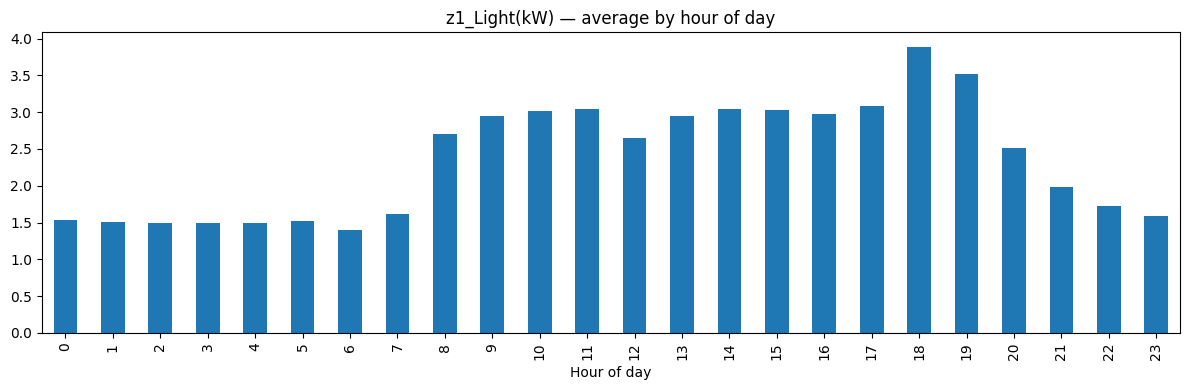

In [14]:
# --- Example: daily / weekly pattern (avg by hour-of-day) ---
if DATE_COL:
    tmp = df[[DATE_COL, COL_TO_PLOT]].dropna().copy()
    tmp['hour'] = tmp[DATE_COL].dt.hour
    hourly_profile = tmp.groupby('hour')[COL_TO_PLOT].mean()

    fig, ax = plt.subplots()
    hourly_profile.plot(kind='bar', ax=ax)
    ax.set_title(f'{COL_TO_PLOT} — average by hour of day')
    ax.set_xlabel('Hour of day')
    plt.tight_layout()
    plt.show()


## 7. Correlation snapshot

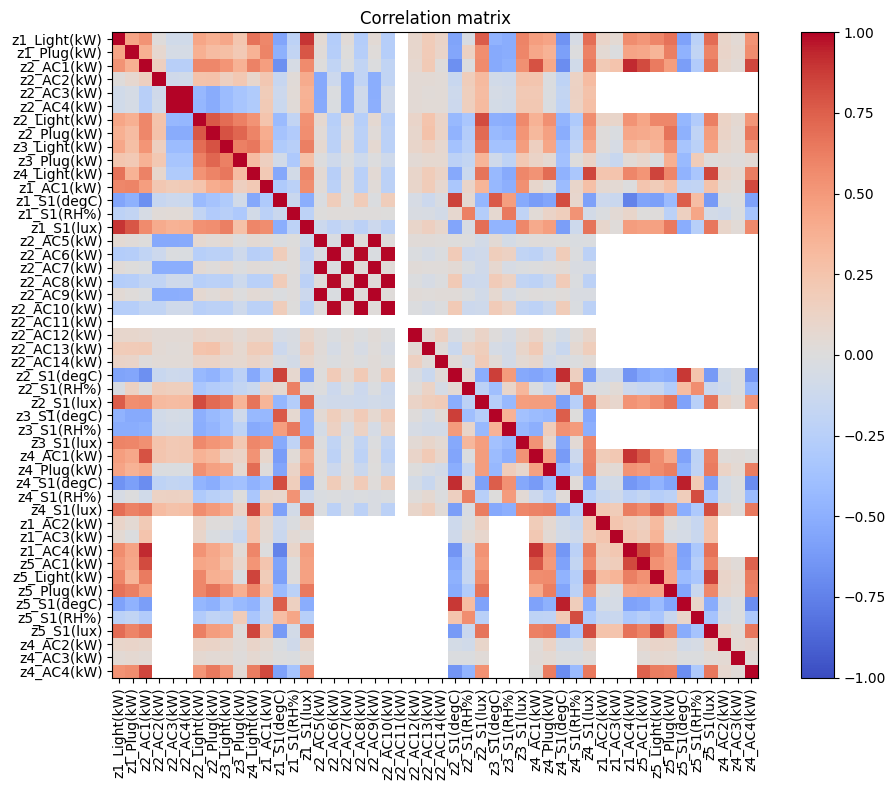

In [15]:
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=90)
ax.set_yticks(range(len(numeric_cols)))
ax.set_yticklabels(numeric_cols)
fig.colorbar(im)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()


## 8. Next steps / notes

- [ ] Confirm real column names & date parsing above
- [ ] Decide which floor(s)/zone(s) to focus on (per project brief: start narrow, one floor + manageable period)
- [ ] Document data quality issues found (missing %, gaps, outliers)
- [ ] Once EDA is solid, move toward your two project questions (baseline, anomaly detection, forecasting, etc.)
